# 08 — Garder les mots-clés : fine-tuning mélangé et coup de pouce

Le notebook 07 a appris la forme (4 vers courts), mais il a fait **oublier**
au modèle une partie de l'usage des mots-clés : 7,4 % de mots repris sans
meilleur de N, contre 15,6 % avant le fine-tuning. C'est l'**oubli
catastrophique** (*catastrophic forgetting*) : en s'adaptant à 1 600
comptines, le modèle a perdu une partie de ce qu'il savait.

Ce notebook s'y attaque à deux niveaux :

1. **à l'entraînement** — un fine-tuning **mélangé** : des histoires
   TinyStories au milieu des comptines (*rehearsal*), pour que le modèle
   continue à pratiquer la consigne pendant qu'il apprend la forme. On choisit
   le modèle sur un score qui compte les mots repris et les rimes, pas
   seulement la loss ;
2. **à la génération** — un **coup de pouce** sur les mots-clés pas encore
   écrits (*logit bias*), combiné au **meilleur de N**.

Mélanger des histoires aux comptines pose un problème : si la consigne est la
même pour les deux (`words: …`), le modèle ne peut pas savoir quel genre on
attend de lui, et il écrit parfois une histoire au lieu d'une comptine (c'est
ce qu'a montré une première version de ce notebook). On donne donc **une
consigne différente à chaque genre** : `rhyme: …` pour les comptines,
`words: …` pour les histoires.

Le modèle écrit toujours chaque comptine lui-même, token par token. On
vérifie aussi qu'il **n'en récite pas** du corpus.

In [1]:
import copy
import json
import math
import random
import re
import shutil
import time
from contextlib import nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import ConcatDataset, DataLoader, SequentialSampler, WeightedRandomSampler
from torch.utils.tensorboard import SummaryWriter

from comptines import (BPETokenizer, GPTLanguageModel, TokenTextDataset, best_of_n, content_words, keyword_hits,
                       poem_score, rhyme_rate, write_texts)

In [2]:
SEED = 1337
torch.manual_seed(SEED)
random.seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
BPE_DIR = DATA_DIR / "bpe"
CHECKPOINT_DIR = ROOT / "checkpoints"
RUNS_DIR = ROOT / "runs" / "08_finetuning_melange"
FINAL_PATH = CHECKPOINT_DIR / "gpt_comptines_v2.pt"
N_LINES = 4

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"device : {device}")

device : cuda


## 1. Les données : comptines de 4 vers et histoires

Les comptines de 4 vers du notebook 07, et les histoires TinyStories du
notebook 04. Tous les exemples ont la même taille (256 tokens) pour pouvoir
être mis dans les mêmes lots.

### Une consigne par genre

Le premier mot de la consigne dit au modèle quel **genre** de texte écrire :

```
rhyme: cat, moon          ← une comptine de 4 vers
words: cat, moon          ← une histoire, comme depuis le notebook 05
```

C'est un *control code* : le modèle CTRL (Keskar et al., 2019) préfixait
chaque texte de sa source (`Wikipedia`, `Reviews`…), T5 préfixe chaque tâche
(`translate English to German: …`). Ici, les histoires gardent `words:`, la
consigne que le modèle connaît depuis 13 000 pas, et les comptines reçoivent
`rhyme:`, un début qu'il n'a jamais vu et qu'il associera à la forme
comptine. À la génération, on demandera `rhyme:`.

In [3]:
tokenizer = BPETokenizer(json.loads((BPE_DIR / "vocab.json").read_text()))
idf = json.loads((BPE_DIR / "idf.json").read_text())


def four_lines(path: Path) -> list[str]:
    """Les comptines d'exactement 4 lignes d'un fichier du notebook 01."""
    return [r for r in path.read_text(encoding="utf-8").split("\n\n") if r.count("\n") + 1 == N_LINES]


def pack(texts: list[str]) -> dict:
    """Tokenise des textes et les range en `ids` / `offsets` / `keywords` (comme au notebook 04)."""
    encoded = [tokenizer.encode(t) for t in texts]
    offsets = torch.tensor([0] + [len(e) for e in encoded]).cumsum(0)
    ids = torch.tensor([i for e in encoded for i in e], dtype=torch.int32)
    return {"ids": ids, "offsets": offsets, "keywords": [content_words(t) for t in texts]}


train_rhymes = four_lines(DATA_DIR / "comptines_train.txt")
val_rhymes = four_lines(DATA_DIR / "comptines_val.txt")
block_size = 256
GENRE = "rhyme"  # la consigne des comptines ; les histoires gardent "words"
rhymes_train = TokenTextDataset(pack(train_rhymes), tokenizer, block_size, idf=idf, genre=GENRE)
rhymes_val = TokenTextDataset(pack(val_rhymes), tokenizer, block_size, fixed_keywords=True, idf=idf, genre=GENRE)
stories_train = TokenTextDataset(torch.load(BPE_DIR / "tinystories_train.pt"), tokenizer, block_size, idf=idf)
print(f"{len(rhymes_train):,} comptines de 4 vers   {len(stories_train):,} histoires   {len(rhymes_val):,} comptines de validation")
for name, ds in [("comptine", rhymes_train), ("histoire", stories_train)]:
    x, y = ds[0]
    first = int((y != -1).nonzero().min())  # première cible notée : la consigne s'arrête en x[first]
    print(f"consigne d'une {name} : {tokenizer.decode(x[: first + 1].tolist())!r}")

1,593 comptines de 4 vers   54,849 histoires   174 comptines de validation
consigne d'une comptine : 'rhyme: grieved, sore, loss\n'
consigne d'une histoire : 'words: course, smiled\n'


### Le mélange

On tire les exemples d'un `ConcatDataset` (comptines puis histoires) avec un
`WeightedRandomSampler` : chaque exemple reçoit un poids, et il est tiré avec
une probabilité proportionnelle. Les poids sont réglés pour qu'**un exemple
sur trois soit une histoire** et deux sur trois des comptines, quelle que soit
la taille des deux corpus.

- Les comptines apprennent la **forme** : 4 vers courts.
- Les histoires entretiennent la **consigne** : dans TinyStories, les mots-clés
  (tirés avec l'IDF) sont des mots que le modèle connaît bien, et il s'est
  entraîné 13 000 pas à les reprendre.

C'est le *rehearsal* (répétition) : on continue de montrer au modèle des
exemples de ce qu'il ne doit pas oublier.

In [4]:
story_share = 1 / 3
mixed = ConcatDataset([rhymes_train, stories_train])
weights = torch.cat([torch.full((len(rhymes_train),), (1 - story_share) / len(rhymes_train)),
                     torch.full((len(stories_train),), story_share / len(stories_train))])

batch_size = 32
max_steps = 1_500
sampler = WeightedRandomSampler(weights, num_samples=max_steps * batch_size, replacement=True,
                                generator=torch.Generator().manual_seed(SEED))
train_loader = DataLoader(mixed, batch_size=batch_size, sampler=sampler)

X, Y = next(iter(train_loader))
n_stories = sum(int((y != -1).sum()) > 80 for y in Y)  # une comptine fait moins de 80 tokens notés
print(f"un lot : {len(X) - n_stories} comptines et {n_stories} histoires (attendu ≈ {batch_size * story_share:.0f})")

un lot : 20 comptines et 12 histoires (attendu ≈ 11)


## 2. Choisir le modèle sur ce qu'on veut vraiment

Jusqu'ici, on gardait le pas de **plus basse loss de validation**. Mais la
loss ne mesure pas l'usage des mots-clés : au notebook 07, elle s'est
améliorée pendant que le modèle les oubliait.

Ici, tous les 250 pas, on fait aussi **écrire** le modèle sur 60 consignes de
validation (sans coup de pouce ni meilleur de N : le modèle seul) et on
calcule

$$\text{score de sélection} = \text{mots-clés repris} + 0{,}5 \times \text{vers qui riment}$$

On garde le pas qui a le meilleur score. La loss de validation est toujours
mesurée et affichée, pour vérifier qu'elle ne se dégrade pas.

In [5]:
config = {**torch.load(CHECKPOINT_DIR / "gpt_bpe_mots_cles.pt", map_location="cpu")["config"], "dropout": 0.2}


def load(path: Path, cfg: dict | None = None) -> GPTLanguageModel:
    """Recharge un modèle sauvegardé (avec une configuration éventuellement modifiée)."""
    ckpt = torch.load(path, map_location=device)
    m = GPTLanguageModel(**(cfg or ckpt["config"])).to(device)
    m.load_state_dict(ckpt["model_state"])
    return m


def autocast():
    """Calcul en bfloat16 sur GPU, rien de spécial sur CPU."""
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()


warmup_steps = 50
max_lr = 3e-4
min_lr = 3e-5
eval_every = 250
selection_sets = [rhymes_val.keywords_of(i) for i in range(60)]


def lr_at(step: int) -> float:
    """Learning rate au pas `step` : montée linéaire, puis cosinus de `max_lr` à `min_lr`."""
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, max_steps - warmup_steps)
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))


@torch.no_grad()
def test(model: nn.Module, dataset: TokenTextDataset) -> float:
    """Loss moyenne par token noté, sur tout le dataset."""
    model.eval()
    total, count = 0.0, 0
    for X, Y in DataLoader(dataset, batch_size=batch_size, sampler=SequentialSampler(dataset)):
        with autocast():
            _, loss = model(X.to(device), Y.to(device))
        n = (Y != -1).sum().item()
        total, count = total + loss.item() * n, count + n
    return total / count


def selection_score(model: nn.Module) -> tuple[float, float, float]:
    """Mots repris, vers qui riment et score de sélection, sur les consignes de sélection."""
    torch.manual_seed(SEED)
    texts = write_texts(model, tokenizer, selection_sets, n_lines=N_LINES, max_batch=64, genre=GENRE)
    hits = sum(keyword_hits(k, t) for k, t in zip(selection_sets, texts)) / len(texts)
    rhymes = sum(map(rhyme_rate, texts)) / len(texts)
    return hits, rhymes, hits + 0.5 * rhymes

In [6]:
def train_step(model: nn.Module, optimizer: torch.optim.Optimizer, X: torch.Tensor, Y: torch.Tensor) -> float:
    """Un pas d'entraînement sur un lot ; renvoie la loss du lot."""
    model.train()  # dropout actif
    with autocast():
        _, loss = model(X.to(device), Y.to(device))  # 1. forward, loss comprise
    optimizer.zero_grad(set_to_none=True)
    loss.backward()  # 2. backward
    optimizer.step()  # 3. step
    return loss.item()


def measure(model: nn.Module, step: int, train_loss: float, history: list, writer: SummaryWriter) -> float:
    """Loss de validation et score de sélection au pas `step` ; renvoie le score."""
    val_loss = test(model, rhymes_val)
    hits, rhymes, score = selection_score(model)
    if device == "cuda":
        torch.cuda.empty_cache()  # rend au GPU la mémoire de la génération : à 4 Go, Windows déborderait en RAM, 5 fois plus lente
    history.append((step, train_loss, val_loss, hits, rhymes, score))
    if step > 0:
        writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, step)
    writer.add_scalars("selection", {"mots repris": hits, "rimes": rhymes, "score": score}, step)
    print(f"pas {step:>5,}   train {train_loss:6.3f}   val {val_loss:.3f}   mots {hits:5.1%}   rimes {rhymes:5.1%}   score {score:.3f}")
    return score


def run_training(model: nn.Module, run: str) -> dict:
    """Fine-tune sur le mélange, et recharge à la fin les poids du meilleur score de sélection."""
    torch.manual_seed(SEED)
    log_dir = RUNS_DIR / run
    shutil.rmtree(log_dir, ignore_errors=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr)
    train_losses, history = [], []
    start = time.perf_counter()

    with SummaryWriter(log_dir=str(log_dir)) as writer:
        best_score, best_step, best_state = measure(model, 0, float("nan"), history, writer), 0, copy.deepcopy(model.state_dict())
        for step, (X, Y) in enumerate(train_loader, start=1):
            for group in optimizer.param_groups:
                group["lr"] = lr_at(step - 1)
            train_losses.append(train_step(model, optimizer, X, Y))
            if step % eval_every == 0:
                score = measure(model, step, sum(train_losses) / len(train_losses), history, writer)
                train_losses = []
                if score > best_score:
                    best_score, best_step, best_state = score, step, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    print(f"\n[{run}] {max_steps:,} pas   {time.perf_counter() - start:.0f} s   meilleur score {best_score:.3f} au pas {best_step:,}")
    return {"history": history, "best_step": best_step, "best_score": best_score}


model = load(CHECKPOINT_DIR / "gpt_bpe_mots_cles.pt", config)
print("point de départ : le modèle du notebook 06 (avant tout fine-tuning)")
result = run_training(model, "melange")

# Sauvegarde dès la fin de l'entraînement : la génération qui suit est longue, rien ne doit se perdre.
torch.save({"model_state": model.state_dict(), "config": config, "gpt2_ids": tokenizer.gpt2_ids,
            "history": result["history"]}, FINAL_PATH)
if device == "cuda":
    torch.cuda.empty_cache()  # libère la mémoire de l'entraînement avant la génération

point de départ : le modèle du notebook 06 (avant tout fine-tuning)


pas     0   train    nan   val 7.513   mots  7.8%   rimes  3.1%   score 0.093


pas   250   train  2.680   val 4.256   mots 14.7%   rimes  1.2%   score 0.153


pas   500   train  2.306   val 3.929   mots 15.3%   rimes  0.8%   score 0.157


pas   750   train  2.123   val 3.715   mots 13.1%   rimes  1.9%   score 0.140


pas 1,000   train  2.025   val 3.657   mots 10.8%   rimes  2.5%   score 0.121


pas 1,250   train  1.964   val 3.568   mots 11.1%   rimes  1.7%   score 0.119


pas 1,500   train  1.928   val 3.545   mots 11.7%   rimes  1.7%   score 0.125

[melange] 1,500 pas   574 s   meilleur score 0.157 au pas 500


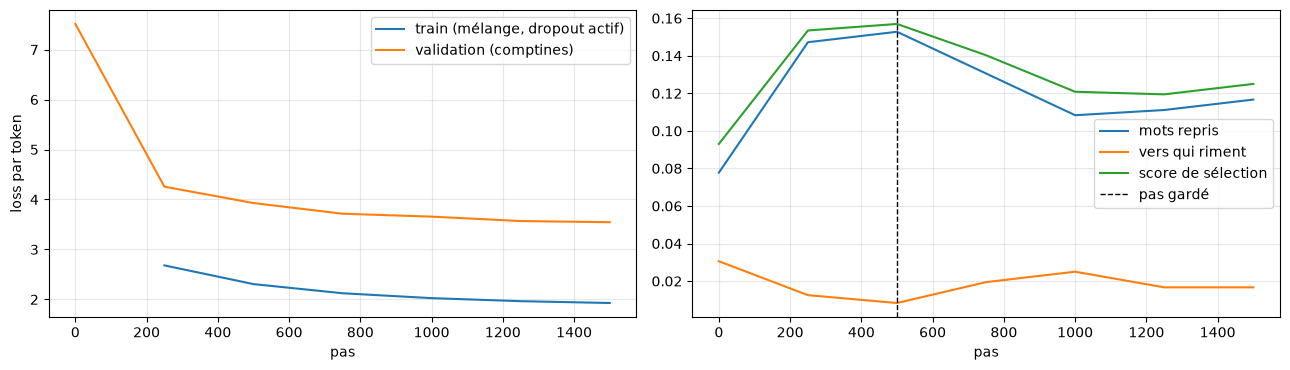

In [7]:
steps, train_curve, val_curve, hits_curve, rhymes_curve, score_curve = zip(*result["history"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(steps[1:], train_curve[1:], label="train (mélange, dropout actif)")
axes[0].plot(steps, val_curve, label="validation (comptines)")
axes[0].set_ylabel("loss par token")
axes[1].plot(steps, hits_curve, label="mots repris")
axes[1].plot(steps, rhymes_curve, label="vers qui riment")
axes[1].plot(steps, score_curve, label="score de sélection")
axes[1].axvline(result["best_step"], color="black", linestyle="--", linewidth=1, label="pas gardé")
for ax in axes:
    ax.set_xlabel("pas")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Le coup de pouce sur les mots-clés

Pendant la génération, on ajoute un bonus `b` aux logits des tokens des
mots-clés **pas encore écrits**, juste avant le top-k :

$$\text{logit}'(t) = \frac{\text{logit}(t)}{T} + b \quad \text{si } t \text{ continue un mot-clé pas encore écrit}$$

Un bonus de `b` multiplie la probabilité du token par environ `e^b` avant
normalisation (`e^4 ≈ 55`, `e^6 ≈ 400`). Le modèle reste libre : il choisit
**où** placer le mot et comment construire le vers autour. Dès que le mot est
écrit, son bonus disparaît. C'est une stratégie de tirage, comme la
température et le top-k (script 07 du cours) : le modèle n'est pas modifié.

`KeywordTracker` (module `comptines.py`) suit les mots **token par token** :

- un mot rare peut faire plusieurs tokens. Une fois le début écrit, c'est la
  suite *de ce mot* qui reçoit le bonus ;
- on ne favorise que des formes qui commencent par un vrai morceau de mot
  (au moins 2 caractères), et on abandonne un mot après 3 débuts ratés : sans
  ces garde-fous, le modèle peut boucler sur une lettre (`ltyltylty…`).

Quel bonus choisir ? Mesurons sur les 174 comptines de validation :

In [8]:
keyword_sets = [k for k in (rhymes_val.keywords_of(i) for i in range(len(rhymes_val))) if k]


def describe(texts: list[str]) -> dict[str, float]:
    """Les mesures d'un ensemble de textes générés pour `keyword_sets`."""
    n = len(texts)
    shifted = texts[1:] + texts[:1]
    lines = [[line for line in t.split("\n") if line.strip()] for t in texts]
    return {
        "mots repris": sum(keyword_hits(k, t) for k, t in zip(keyword_sets, texts)) / n,
        "tous les mots": sum(keyword_hits(k, t) == 1 for k, t in zip(keyword_sets, texts)) / n,
        "référence": sum(keyword_hits(k, t) for k, t in zip(keyword_sets, shifted)) / n,
        "vers qui riment": sum(map(rhyme_rate, texts)) / n,
        "4 vers": sum(len(l) == N_LINES for l in lines) / n,
        "mots par vers": sum(len(line.split()) for l in lines for line in l) / max(1, sum(map(len, lines))),
    }


boosts = [0, 2, 4, 6, 8]
sweep = {}
for b in boosts:
    torch.manual_seed(SEED)
    sweep[b] = describe(write_texts(model, tokenizer, keyword_sets, n_lines=N_LINES, max_batch=64, keyword_boost=b,
                                    genre=GENRE))
    print(f"bonus {b}:  mots repris {sweep[b]['mots repris']:5.1%}   tous les mots {sweep[b]['tous les mots']:5.1%}   "
          f"vers qui riment {sweep[b]['vers qui riment']:5.1%}")

bonus 0:  mots repris 20.7%   tous les mots 11.5%   vers qui riment  2.7%


bonus 2:  mots repris 34.7%   tous les mots 20.7%   vers qui riment  2.2%


bonus 4:  mots repris 43.9%   tous les mots 27.0%   vers qui riment  1.7%


bonus 6:  mots repris 60.5%   tous les mots 38.5%   vers qui riment  3.9%


bonus 8:  mots repris 74.0%   tous les mots 60.3%   vers qui riment  2.9%


Plus le bonus est fort, plus les mots-clés sont repris. Mais plus on force
aussi la main au modèle : il place le mot là où il ne l'aurait pas mis. On
retient **`b = 6`** comme compromis, puis le meilleur de N fait le reste.

## 4. Le meilleur de N : priorité aux mots-clés, pas de prose

Deux changements au score du notebook 07 (`mots repris + 0,5 × rimes − 1 si
pas 4 vers`) :

- **les mots-clés comptent double** (`keyword_weight = 2`) : une comptine qui
  contient **tous** les mots passe devant, et les rimes départagent ensuite ;
- **une pénalité sur les lignes trop longues** (`max_words = 12`) : on retire
  la part des vers de plus de 12 mots. Une ligne de prose n'est pas un vers :
  dans les vraies comptines de 4 vers, 0,1 % des vers dépassent 12 mots.

In [9]:
BOOST = 6
N_BEST = 8
KEYWORD_WEIGHT = 2.0
MAX_WORDS = 12


def pick_best(pool: list[str]) -> list[str]:
    """Pour chaque consigne, la meilleure de ses `N_BEST` candidates (rangées à la suite dans `pool`)."""
    return [max(pool[i * N_BEST : (i + 1) * N_BEST],
                key=lambda t: poem_score(k, t, N_LINES, KEYWORD_WEIGHT, MAX_WORDS))
            for i, k in enumerate(keyword_sets)]


def write(m: GPTLanguageModel, sets: list[list[str]], genre: str = GENRE, boost: float = 0.0) -> list[str]:
    torch.manual_seed(SEED)
    return write_texts(m, tokenizer, sets, n_lines=N_LINES, max_batch=64, keyword_boost=boost, genre=genre)


repeated = [k for k in keyword_sets for _ in range(N_BEST)]
model_07 = load(CHECKPOINT_DIR / "gpt_comptines_final.pt")
generated = {
    "07 seul": write(model_07, keyword_sets, genre="words"),  # le modèle 07 a appris la consigne words:
    "08 seul": write(model, keyword_sets),
    "08 + coup de pouce": write(model, keyword_sets, boost=BOOST),
    "08 + meilleur de 8": pick_best(write(model, repeated)),
    "08 + les deux": pick_best(write(model, repeated, boost=BOOST)),
}
results = {name: describe(texts) for name, texts in generated.items()}

## 5. Le modèle récite-t-il le corpus ?

Avec 1 600 comptines d'entraînement, un modèle fine-tuné peut apprendre des
vers **par cœur** et les ressortir. Ce ne serait plus de la génération. On
mesure, pour chaque texte généré, la part de ses vers qui existent **tels
quels** dans les comptines d'entraînement (en comparant les lettres seules,
sans ponctuation ni majuscules ; les vers de moins de 3 mots sont ignorés,
`And so will I` n'est pas une copie).

Repère : la même mesure sur les **vraies comptines de validation**. Elles
n'ont jamais servi à l'entraînement, mais les recueils se recopient entre
eux : certains de leurs vers existent aussi dans le train.

In [10]:
def normalize(line: str) -> str:
    return " ".join(re.findall(r"[a-z]+", line.lower()))


train_lines = {normalize(line) for r in train_rhymes for line in r.split("\n")}


def copied_lines(texts: list[str]) -> float:
    """Part des vers (d'au moins 3 mots) qui existent tels quels dans les comptines d'entraînement."""
    lines = [normalize(line) for t in texts for line in t.split("\n")]
    lines = [line for line in lines if len(line.split()) >= 3]
    return sum(line in train_lines for line in lines) / max(1, len(lines))


for name, texts in generated.items():
    results[name]["vers copiés"] = copied_lines(texts)
print(f"vraies comptines de validation : {copied_lines(val_rhymes):.1%} de vers déjà présents dans le train")

vraies comptines de validation : 33.9% de vers déjà présents dans le train


## 6. Le bilan

In [11]:
# Bits par caractère (notebook 07) : loss moyenne × nombre de tokens notés = loss totale, / caractères, / ln 2.
n_tokens = sum(int((rhymes_val[i][1] != -1).sum()) for i in range(len(rhymes_val)))
n_chars = sum(len(r) for r in val_rhymes)
bpc = {name: test(m, rhymes_val) * n_tokens / n_chars / math.log(2)
       for name, m in [("07 seul", model_07), ("08 seul", model)]}

columns = ["mots repris", "tous les mots", "référence", "vers qui riment", "4 vers", "mots par vers", "vers copiés"]
print(f"{'':20} {'bits/car.':>9} " + " ".join(f"{c:>15}" for c in columns))
for name, res in results.items():
    bpc_txt = f"{bpc[name]:9.2f}" if name in bpc else f"{'':9}"
    print(f"{name:20} {bpc_txt} " + " ".join(
        f"{res[c]:>15.1f}" if c == "mots par vers" else f"{res[c]:>15.1%}" for c in columns))
truth = describe(val_rhymes)
print(f"{'vraies comptines':20} {'':9} {'':>15} {'':>15} {'':>15} {truth['vers qui riment']:>15.1%} "
      f"{truth['4 vers']:>15.1%} {truth['mots par vers']:>15.1f} {copied_lines(val_rhymes):>15.1%}")

                     bits/car.     mots repris   tous les mots       référence vers qui riment          4 vers   mots par vers     vers copiés
07 seul                   1.55            7.4%            3.4%            1.8%            7.1%           87.4%             6.3           26.8%
08 seul                   1.75           20.7%           11.5%            1.2%            2.7%           60.9%             6.6            1.3%
08 + coup de pouce                       60.5%           38.5%            1.1%            3.9%           63.2%             6.3            0.7%
08 + meilleur de 8                       39.8%           23.0%            0.9%            7.3%           96.0%             6.2            0.9%
08 + les deux                            80.9%           66.1%            1.2%            8.6%           98.9%             5.9            1.0%
vraies comptines                                                                         41.2%          100.0%             6.5           33.9%

Les lignes « seul » mesurent ce que le **modèle** sait faire, les autres ce
qu'on obtient avec la **stratégie de génération** (coup de pouce, meilleur
de N). Les deux sont à présenter ensemble.

## 7. Démonstration

Coup de pouce et meilleur de 8, avec des mots qu'un utilisateur pourrait
donner :

In [12]:
torch.manual_seed(SEED)
for words in [["moon", "cat", "dog"], ["king", "pie"], ["rain", "garden"], ["dog", "bone", "star"],
              ["girl", "ball", "happy"], ["mouse", "cheese"], ["sun", "sea", "boat"]]:
    best, _ = best_of_n(model, tokenizer, words, n=N_BEST, keyword_weight=KEYWORD_WEIGHT, max_words=MAX_WORDS,
                        keyword_boost=BOOST, genre=GENRE)
    found = [w for w in words if keyword_hits([w], best)]
    print(f"--- {', '.join(words)}   (repris : {', '.join(found) or 'aucun'}, rimes {rhyme_rate(best):.0%}) ---")
    print(best, end="\n\n")

--- moon, cat, dog   (repris : moon, cat, dog, rimes 0%) ---
Dog is on a moon,
I hope a cat,
And a little dog is a cat,
And he brings a kiss on the moon.



--- king, pie   (repris : king, pie, rimes 0%) ---
If pie was for King
"King, King, will I have a little cut our pie?
If you did, you have no pie?
You must be a King, he will be a plain,



--- rain, garden   (repris : rain, garden, rimes 0%) ---
As rain blows the garden,
What shall I do?
What to do? says the windy sun?
"I would rock the flowers and see them stay."



--- dog, bone, star   (repris : dog, bone, star, rimes 0%) ---
There was an old man who lived in a star,
He had a dog never heard,
And all his bone broke,
And it was all in a trap.



--- girl, ball, happy   (repris : girl, ball, rimes 0%) ---
When I was a girl,
I'll dress my ball,
I'll put it up with my pocket and catch it,
And you can dress it up again,



--- mouse, cheese   (repris : mouse, cheese, rimes 0%) ---
She went to the cheese
To buy him some cheese,
He found a mouse,
He gave it to his wife and said the mouse, "Yes."



--- sun, sea, boat   (repris : sun, sea, boat, rimes 0%) ---
The boat was on sea, and the sun shone,
And there was an old man who lived by the sea.
He loved to fly his boat, and play with the little boat,
And that's how kind of help:



## 8. Sauvegarder

Le modèle et ses réglages de génération, utilisés par `generer.py`.

In [13]:
torch.save({
    "model_state": model.state_dict(),
    "config": config,
    "gpt2_ids": tokenizer.gpt2_ids,
    "history": result["history"],
    "results": results,
    "generation": {"keyword_boost": BOOST, "n": N_BEST, "keyword_weight": KEYWORD_WEIGHT, "max_words": MAX_WORDS,
                   "genre": GENRE},
}, FINAL_PATH)
print(f"→ {FINAL_PATH.relative_to(ROOT)}")

→ checkpoints\gpt_comptines_v2.pt
